# Day 3 - Train the DNN and the CNN (Member A)

Steps:
1. load the data from Day 2
2. prepare class weights
3. DNN: build, train, measure, save
4. CNN: build, train, measure, save
5. compare the two

The functions live in `src/train_models.py`. Here we call them one by one.
Training takes some minutes. Do not close VS Code while a cell shows `[*]`.

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath("../src"))
import train_models as tm

print("Ready")

Ready


## Settings

- `EPOCHS`: the most epochs one model can train for. Early stopping usually stops sooner.
- `BATCH_SIZE`: how many rows the model sees before it updates itself.
- `WEIGHT_MODE`: how much extra attention small classes (like Worms) get.
  - `"balanced"`: full weights (small classes count a lot, can make training unstable)
  - `"sqrt"`: a softer version (the default here)
  - `"none"`: no weights

In [2]:
EPOCHS = 40
BATCH_SIZE = 256
WEIGHT_MODE = "sqrt"

## 1. Load the data from Day 2

In [3]:
data, class_names, raw_weights = tm.load_data()

for name, arr in data.items():
    print(name, arr.shape)

n_features = data["X_train"].shape[1]
n_classes = len(class_names)
print()
print("Features:", n_features, "| Classes:", n_classes)
print(class_names)

X_train (91579, 30)
y_train (91579,)
X_val (16161, 30)
y_val (16161,)
X_test (82332, 30)
y_test (82332,)

Features: 30 | Classes: 10
['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']


## 2. Class weights

In [4]:
class_weight = tm.make_class_weights(raw_weights, WEIGHT_MODE)

table = pd.DataFrame({
    "class": class_names,
    "balanced weight": [round(raw_weights[i], 2) for i in range(n_classes)],
    "weight used": [None if class_weight is None else round(class_weight[i], 2)
                    for i in range(n_classes)],
})
table

,class,balanced weight,weight used
0,Analysis,6.76,2.60
1,Backdoor,7.02,2.65
2,DoS,2.83,1.68
3,Exploits,0.54,0.74
4,Fuzzers,0.67,0.82
5,Generic,2.58,1.61
6,Normal,0.21,0.46
7,Reconnaissance,1.43,1.20
8,Shellcode,9.88,3.14
9,Worms,84.80,9.21


Small classes get a bigger weight, so a mistake on a Worms row costs the model more than a mistake on a Normal row.

## 3. DNN (Deep Neural Network)

A stack of fully connected layers: 128, 64 and 32 neurons, with Dropout (randomly switches neurons off so the model does not just memorize).
The last layer has 10 outputs, one probability per attack type.

In [5]:
tm.set_seed()
dnn = tm.build_dnn(n_features, n_classes)
dnn.summary()

Model: "dnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,146 (59.16 KB)

 Trainable params: 14,890 (58.16 KB)

 Non-trainable params: 256 (1.00 KB)

In [6]:
dnn_history = tm.train_model(
    dnn,
    data["X_train"], data["y_train"],
    data["X_val"], data["y_val"],
    class_weight, EPOCHS, BATCH_SIZE,
)
print("Epochs run:", len(dnn_history["loss"]))

Epoch 1/40
358/358 - 9s - 26ms/step - accuracy: 0.6646 - loss: 1.0262 - val_accuracy: 0.7056 - val_loss: 1.0147 - learning_rate: 0.0010
Epoch 2/40
358/358 - 4s - 11ms/step - accuracy: 0.7078 - loss: 0.8627 - val_accuracy: 0.7305 - val_loss: 0.7488 - learning_rate: 0.0010
Epoch 3/40
358/358 - 4s - 12ms/step - accuracy: 0.7199 - loss: 0.8201 - val_accuracy: 0.7352 - val_loss: 0.7234 - learning_rate: 0.0010
Epoch 4/40
358/358 - 3s - 8ms/step - accuracy: 0.7283 - loss: 0.7890 - val_accuracy: 0.7428 - val_loss: 0.6879 - learning_rate: 0.0010
Epoch 5/40
358/358 - 3s - 8ms/step - accuracy: 0.7350 - loss: 0.7619 - val_accuracy: 0.7427 - val_loss: 0.6807 - learning_rate: 0.0010
Epoch 6/40
358/358 - 4s - 11ms/step - accuracy: 0.7375 - loss: 0.7477 - val_accuracy: 0.7402 - val_loss: 0.6653 - learning_rate: 0.0010
Epoch 7/40
358/358 - 5s - 15ms/step - accuracy: 0.7379 - loss: 0.7350 - val_accuracy: 0.7498 - val_loss: 0.6490 - learning_rate: 0.0010
Epoch 8/40
358/358 - 6s - 18ms/step - accuracy: 0.

### Measure the DNN

`validation` comes from the cleaned training data. `test` comes from the separate test file, so it is the honest score.

In [7]:
dnn_val_probs = tm.predict_probs(dnn, data["X_val"])
dnn_test_probs = tm.predict_probs(dnn, data["X_test"])

dnn_val = tm.compute_metrics(data["y_val"], dnn_val_probs, class_names)
dnn_test = tm.compute_metrics(data["y_test"], dnn_test_probs, class_names)
tm.print_summary("dnn", dnn_val, dnn_test)


==== DNN ====
             validation       test
accuracy               0.7589     0.6510
precision_weighted     0.8369     0.8459
recall_weighted        0.7589     0.6510
f1_weighted            0.7817     0.7061
f1_macro               0.5412     0.4138


In [8]:
rows = {c: dnn_test["per_class"][c] for c in class_names}
pd.DataFrame(rows).T[["precision", "recall", "f1-score", "support"]].round(3)

,precision,recall,f1-score,support
Analysis,0.019,0.154,0.034,677.0
Backdoor,0.063,0.384,0.109,583.0
DoS,0.307,0.075,0.121,4089.0
Exploits,0.785,0.555,0.650,11132.0
Fuzzers,0.229,0.674,0.342,6062.0
Generic,1.000,0.955,0.977,18871.0
Normal,0.997,0.578,0.732,37000.0
Reconnaissance,0.682,0.846,0.755,3496.0
Shellcode,0.120,0.799,0.208,378.0
Worms,0.125,0.659,0.210,44.0


### Save the DNN
This saves `models/dnn_model.h5`, the metrics, the predicted probabilities (used for the ensemble on Day 4) and two graphs.

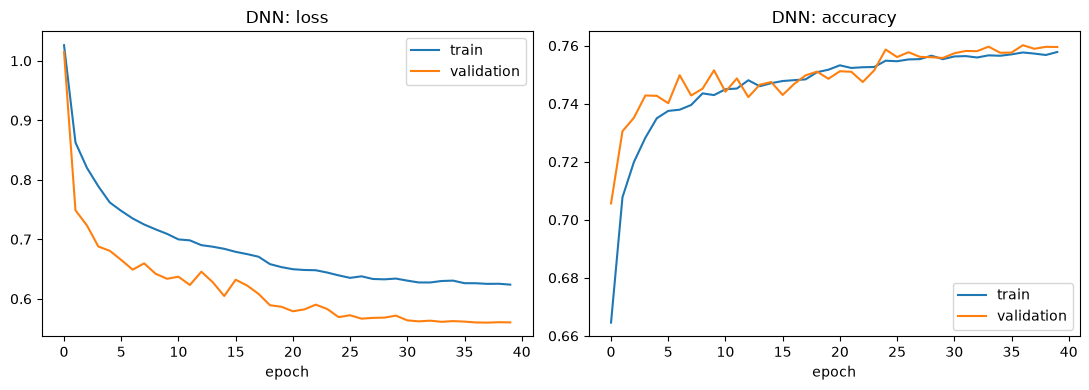

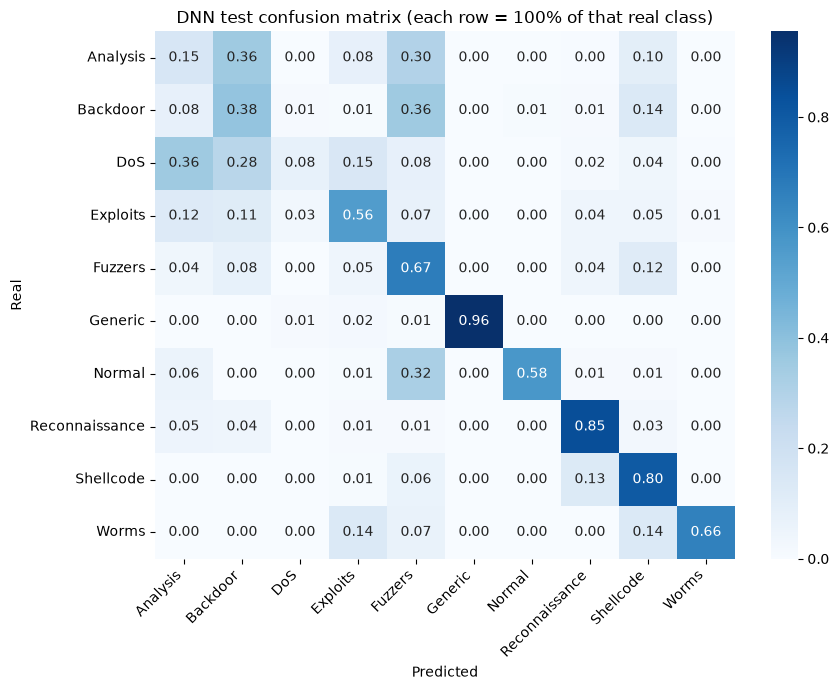

In [9]:
tm.save_results("dnn", dnn, dnn_history, dnn_val_probs, dnn_test_probs,
                dnn_val, dnn_test, class_names)
plt.show()

## 4. CNN (1D Convolutional Neural Network)

The CNN slides small filters across the 30 features to look for patterns between neighbouring features.
It needs the input shaped as `(rows, 30, 1)`, which `reshape_for_cnn` does.

In [10]:
Xtr_c = tm.reshape_for_cnn(data["X_train"])
Xva_c = tm.reshape_for_cnn(data["X_val"])
Xte_c = tm.reshape_for_cnn(data["X_test"])
print(Xtr_c.shape, Xva_c.shape, Xte_c.shape)

tm.set_seed()
cnn = tm.build_cnn(n_features, n_classes)
cnn.summary()

(91579, 30, 1) (16161, 30, 1) (82332, 30, 1)


Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 30, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 30, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 15, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 15, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 7, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 896)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │        57,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 83,274 (325.29 KB)

 Trainable params: 83,146 (324.79 KB)

 Non-trainable params: 128 (512.00 B)

In [11]:
cnn_history = tm.train_model(
    cnn,
    Xtr_c, data["y_train"],
    Xva_c, data["y_val"],
    class_weight, EPOCHS, BATCH_SIZE,
)
print("Epochs run:", len(cnn_history["loss"]))

Epoch 1/40
358/358 - 17s - 47ms/step - accuracy: 0.6886 - loss: 0.9693 - val_accuracy: 0.7316 - val_loss: 1.1670 - learning_rate: 0.0010
Epoch 2/40
358/358 - 11s - 30ms/step - accuracy: 0.7239 - loss: 0.8183 - val_accuracy: 0.7504 - val_loss: 0.6871 - learning_rate: 0.0010
Epoch 3/40
358/358 - 10s - 29ms/step - accuracy: 0.7358 - loss: 0.7667 - val_accuracy: 0.7503 - val_loss: 0.6427 - learning_rate: 0.0010
Epoch 4/40
358/358 - 11s - 29ms/step - accuracy: 0.7413 - loss: 0.7376 - val_accuracy: 0.7561 - val_loss: 0.6187 - learning_rate: 0.0010
Epoch 5/40
358/358 - 11s - 31ms/step - accuracy: 0.7450 - loss: 0.7214 - val_accuracy: 0.7514 - val_loss: 0.6228 - learning_rate: 0.0010
Epoch 6/40
358/358 - 15s - 42ms/step - accuracy: 0.7464 - loss: 0.7042 - val_accuracy: 0.7616 - val_loss: 0.6001 - learning_rate: 0.0010
Epoch 7/40
358/358 - 17s - 48ms/step - accuracy: 0.7477 - loss: 0.6956 - val_accuracy: 0.7547 - val_loss: 0.6097 - learning_rate: 0.0010
Epoch 8/40
358/358 - 20s - 56ms/step - ac

### Measure the CNN

In [12]:
cnn_val_probs = tm.predict_probs(cnn, Xva_c)
cnn_test_probs = tm.predict_probs(cnn, Xte_c)

cnn_val = tm.compute_metrics(data["y_val"], cnn_val_probs, class_names)
cnn_test = tm.compute_metrics(data["y_test"], cnn_test_probs, class_names)
tm.print_summary("cnn", cnn_val, cnn_test)


==== CNN ====
             validation       test
accuracy               0.7704     0.6587
precision_weighted     0.8332     0.8372
recall_weighted        0.7704     0.6587
f1_weighted            0.7883     0.7084
f1_macro               0.5508     0.4222


In [13]:
rows = {c: cnn_test["per_class"][c] for c in class_names}
pd.DataFrame(rows).T[["precision", "recall", "f1-score", "support"]].round(3)

,precision,recall,f1-score,support
Analysis,0.033,0.278,0.059,677.0
Backdoor,0.047,0.245,0.079,583.0
DoS,0.368,0.064,0.109,4089.0
Exploits,0.730,0.597,0.657,11132.0
Fuzzers,0.223,0.615,0.327,6062.0
Generic,0.999,0.963,0.980,18871.0
Normal,0.997,0.591,0.742,37000.0
Reconnaissance,0.595,0.831,0.694,3496.0
Shellcode,0.152,0.783,0.255,378.0
Worms,0.226,0.545,0.320,44.0


### Save the CNN

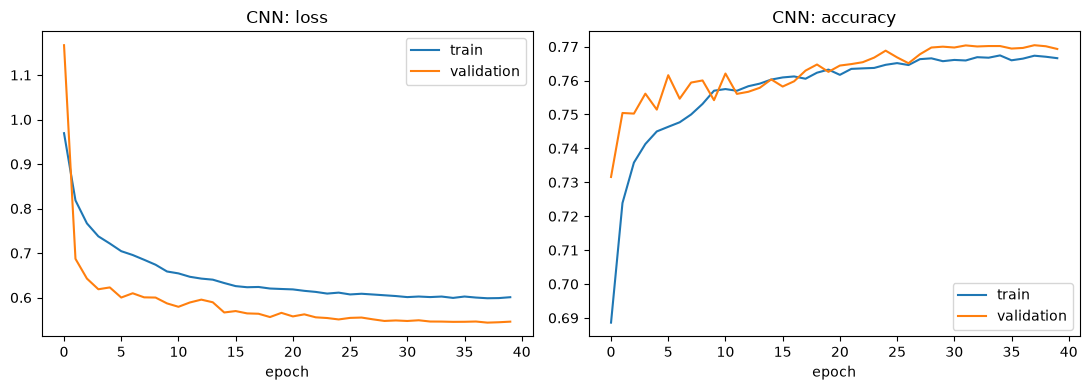

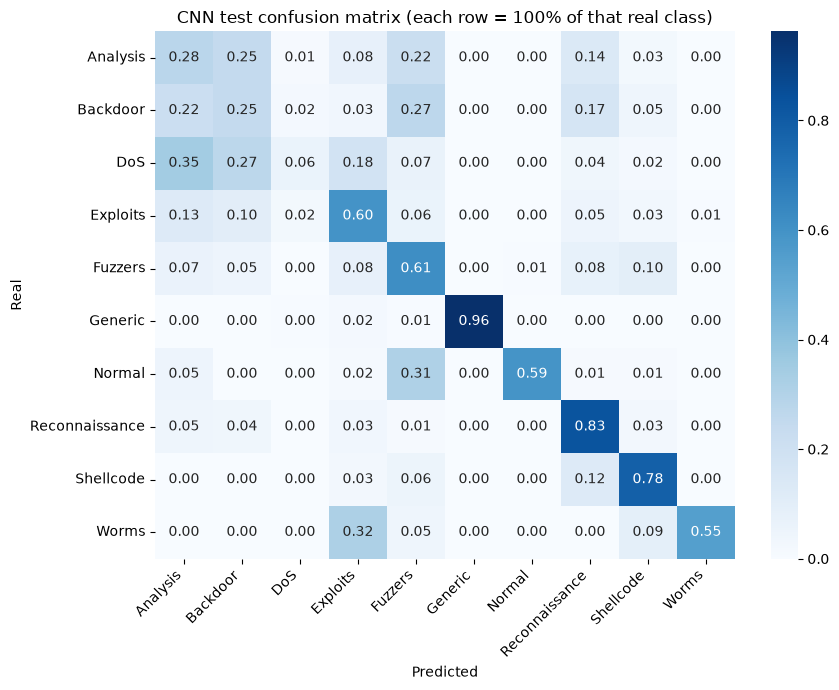

In [14]:
tm.save_results("cnn", cnn, cnn_history, cnn_val_probs, cnn_test_probs,
                cnn_val, cnn_test, class_names)
plt.show()

## 5. Compare DNN and CNN

In [15]:
keys = ["accuracy", "precision_weighted", "recall_weighted", "f1_weighted", "f1_macro"]
compare = pd.DataFrame({
    "DNN validation": [dnn_val[k] for k in keys],
    "DNN test": [dnn_test[k] for k in keys],
    "CNN validation": [cnn_val[k] for k in keys],
    "CNN test": [cnn_test[k] for k in keys],
}, index=keys).round(4)
compare

,DNN validation,DNN test,CNN validation,CNN test
accuracy,0.7589,0.6510,0.7704,0.6587
precision_weighted,0.8369,0.8459,0.8332,0.8372
recall_weighted,0.7589,0.6510,0.7704,0.6587
f1_weighted,0.7817,0.7061,0.7883,0.7084
f1_macro,0.5412,0.4138,0.5508,0.4222


In [16]:
f1 = pd.DataFrame({
    "DNN": [dnn_test["per_class"][c]["f1-score"] for c in class_names],
    "CNN": [cnn_test["per_class"][c]["f1-score"] for c in class_names],
}, index=class_names).round(3)
f1

,DNN,CNN
Analysis,0.034,0.059
Backdoor,0.109,0.079
DoS,0.121,0.109
Exploits,0.650,0.657
Fuzzers,0.342,0.327
Generic,0.977,0.980
Normal,0.732,0.742
Reconnaissance,0.755,0.694
Shellcode,0.208,0.255
Worms,0.210,0.320


## What to check before moving on

- Both models saved: `models/dnn_model.h5` and `models/cnn_model.h5`.
- Validation and test accuracy are not at chance level (10 classes means chance is about 10%).
- Small classes (Worms, Shellcode, Backdoor, Analysis) have a non-zero F1.

## My notes (write in your own words)

- Which model scored better on the test set, and by how much?
- Which attack types were hardest to detect, and why?
- Why is the test score different from the validation score?